# tARget


## Shared ROI


In [1]:
CATALOG = 'tARget'
OUTPUT_NAME = 'target'
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / 'HOME_PROJECT.json').is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from tools import rotated_analysis as rotated, casr_daily as daily
from tools import rotated_plot_style as plot_style
from tools import catalog_comparison as comparison
comparison.apply_plot_style()
cfg = json.loads((ROOT / 'config.json').read_text())

# Editable controls: UTC, with an exclusive end.
START = pd.Timestamp('1980-01-01 00:00')
END = pd.Timestamp('1985-01-01 00:00')
SNAPSHOT_START = pd.Timestamp('1980-01-19 06:00')
SAMPLE_START = START
SAMPLE_END = min(START + pd.Timedelta(days=7), END)
TRACK_ID = None

grid = rotated.prepare_grid(ROOT, cfg)
OUTPUT = rotated.output_directory(ROOT, grid, OUTPUT_NAME)
OUTPUT.mkdir(parents=True, exist_ok=True)

def show(fig, filename):
    plot_style.finish(fig, filename)
    fig.savefig(OUTPUT / filename, dpi=180, facecolor='white')
    plt.show()
    plt.close(fig)

display(rotated.grid_description(grid).to_frame())
print(f'Analysis: {START:%Y-%m-%d} to {END:%Y-%m-%d} (exclusive), UTC.')

,Shared ROI
Native rows × columns,418 × 260
Local row / column positions (stop excluded),[0:418] / [0:260]
Included cells,108680
Rotated latitude centres (°),-29.07 to 8.46
Rotated longitude centres (°),-30.00 to -6.69
rlat cell-edge bounds (°),-29.115002 to 8.505000
rlon cell-edge bounds (°),-30.042221 to -6.642220
Land / ocean / inland water cells,70551 / 37286 / 843


Analysis: 1980-01-01 to 1985-01-01 (exclusive), UTC.


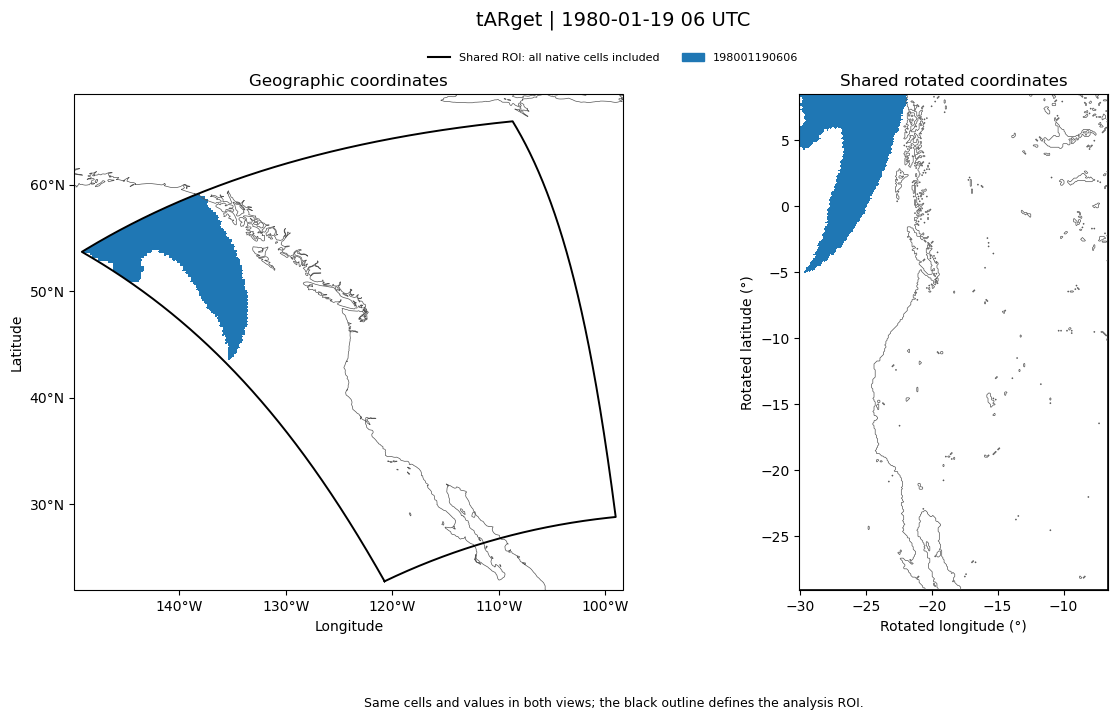

In [2]:
timestamp = SNAPSHOT_START + (pd.Timedelta(hours=3) if CATALOG == 'PIKART' else pd.Timedelta(0))
field, world = rotated.snapshot(ROOT, cfg, grid, CATALOG, timestamp)
show(rotated.plot_coordinate_views(grid, field,
     f'{CATALOG} | {timestamp:%Y-%m-%d %H} UTC', categorical=True),
     '01_roi_coordinates.png')

## Global context


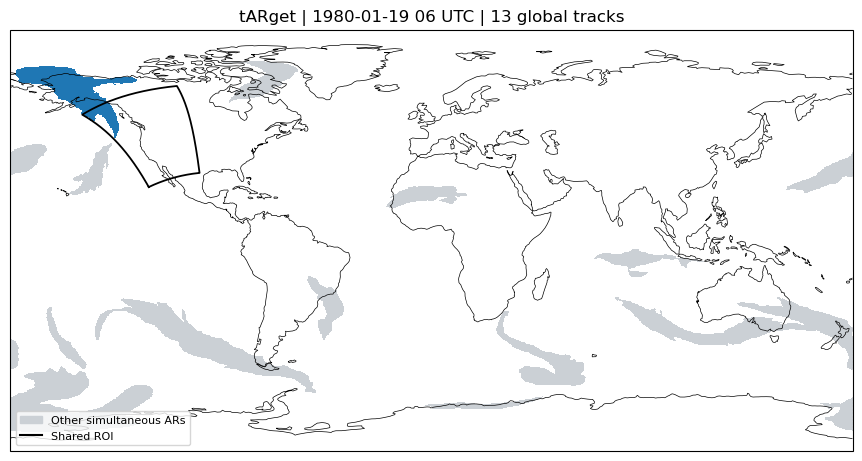

In [3]:
show(rotated.plot_global(grid, world, timestamp, CATALOG,
     np.unique(field[field > 0])), '02_global_context.png')

## Counts and tracking


In [4]:
events = rotated.catalog_analysis(ROOT, cfg, grid, CATALOG, START, END)
display(rotated.catalog_summary(events).to_frame())
failed = events['tracks'].loc[~events['tracks'].verified, ['track_id', 'issue']]
if len(failed):
    display(failed)
else:
    print('All selected IDs pass the catalog consistency checks.')
audit = events['audit']
display(pd.Series({
    'Tracks represented on CaSR grid': audit['native_sampled_tracks'],
    'Source-centre tracks inside the native perimeter': audit['source_centres_inside_tracks'],
    'Inside source-centre tracks not sampled': audit['source_tracks_not_sampled'],
    'Sampled tracks with source centres outside perimeter': audit['sampled_tracks_without_inside_source_centre']
}, name='Sampling audit').to_frame())

tARget native ROI: 1/7,308 snapshots
tARget native ROI: 513/7,308 snapshots
tARget native ROI: 1,025/7,308 snapshots
tARget native ROI: 1,537/7,308 snapshots
tARget native ROI: 2,049/7,308 snapshots
tARget native ROI: 2,561/7,308 snapshots
tARget native ROI: 3,073/7,308 snapshots
tARget native ROI: 3,585/7,308 snapshots
tARget native ROI: 4,097/7,308 snapshots
tARget native ROI: 4,609/7,308 snapshots
tARget native ROI: 5,121/7,308 snapshots
tARget native ROI: 5,633/7,308 snapshots
tARget native ROI: 6,145/7,308 snapshots
tARget native ROI: 6,657/7,308 snapshots
tARget native ROI: 7,169/7,308 snapshots


,tARget
Distinct tracks in shared ROI,1565.000000
Internally consistent tracks,1565.000000
Tracks with unresolved checks,0.000000
Single global detection,422.000000
Median global observed span (h),18.000000
Median detections in ROI,3.000000
Mean six-hour AR area coverage (%),9.070622


All selected IDs pass the catalog consistency checks.


,Sampling audit
Tracks represented on CaSR grid,1565
Source-centre tracks inside the native perimeter,1556
Inside source-centre tracks not sampled,0
Sampled tracks with source centres outside perimeter,9


## Event examples


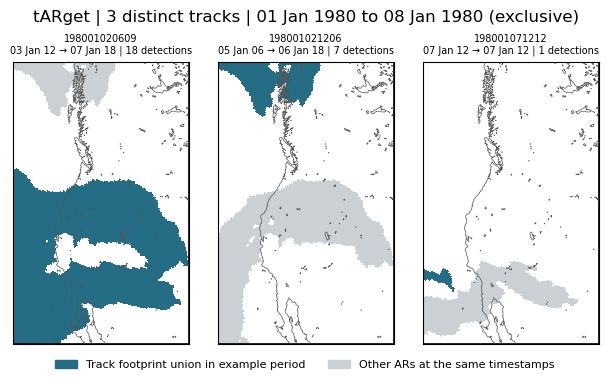

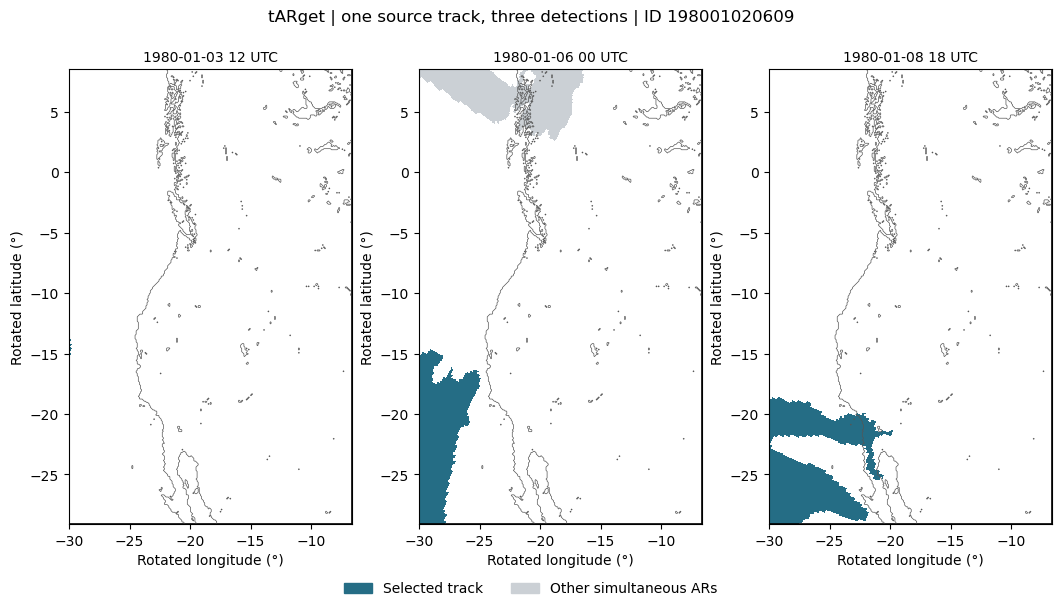

In [5]:
show(rotated.plot_short_gallery(ROOT, cfg, grid, CATALOG, events, SAMPLE_START, SAMPLE_END),
     '03_short_event_gallery.png')
eligible = events['tracks'].loc[lambda f: f.verified & (f.global_detections >= 3) & (f.roi_detections >= 3)]
if TRACK_ID is not None and str(TRACK_ID) not in set(eligible.track_id):
    raise ValueError('Choose a consistent track ID with at least three ROI detections.')
show(rotated.plot_event_samples(ROOT, cfg, grid, CATALOG, events, TRACK_ID),
     '04_one_track_three_detections.png')

## Duration and persistence


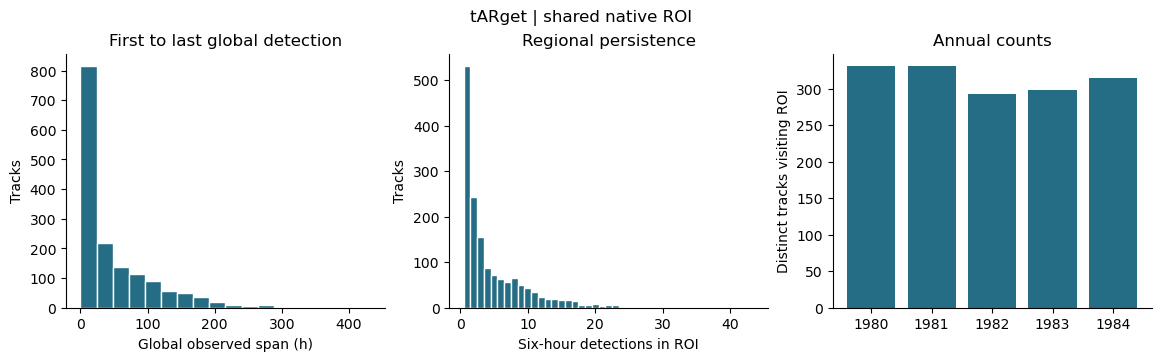

,span_hours,global_detections,roi_detections
count,1565.0,1565.0,1565.0
mean,44.9,8.5,4.8
std,59.2,9.9,5.1
min,0.0,1.0,1.0
25%,0.0,1.0,1.0
50%,18.0,4.0,3.0
75%,72.0,13.0,7.0
max,414.0,70.0,43.0


In [6]:
show(rotated.plot_catalog_statistics(events), '05_event_statistics.png')
verified = events['tracks'].loc[events['tracks'].verified]
display(verified[['span_hours', 'global_detections', 'roi_detections']]
        .describe(percentiles=[0.25, 0.5, 0.75]).round(1))

## Catalog comparison


In [7]:
other_name = 'PIKART' if CATALOG == 'tARget' else 'tARget'
other_manifest = OUTPUT.parent / other_name.lower() / 'catalog_manifest.json'
if other_manifest.exists():
    other = rotated.load_catalog(other_manifest.parent)
    inputs = json.loads(other_manifest.read_text())['inputs']
    assert inputs['start'] == str(START) and inputs['end'] == str(END)
    assert inputs['grid_hash'] == rotated.ar.grid_hash(grid)
    comparison_table = pd.concat([rotated.catalog_summary(events), rotated.catalog_summary(other)], axis=1)
    display(comparison_table[['tARget', 'PIKART']].round(2))
    comparison_table.to_csv(OUTPUT / 'catalog_comparison.csv')
else:
    print(f'Run the {other_name} notebook to populate the shared comparison.')

Run the PIKART notebook to populate the shared comparison.
